# Predicting Customer Term Deposit Subscription Using Supervised Machine Learning

## 1. Project Overview

### 1.1 Background
Banks routinely contact existing customers to promote term-deposit products. A classification model can help identify customers who are more likely to subscribe, allowing campaign teams to focus limited contact resources on higher-probability prospects.

### 1.2 Problem Statement
The dataset contains customer and campaign information together with the outcome of a term-deposit marketing campaign. The main challenge is that the positive class is relatively small, so a model that simply predicts the majority class can appear accurate while failing to identify likely subscribers.

### 1.3 Project Objective
The objective is to develop and compare supervised classification models for predicting whether a customer will subscribe to a term deposit. The analysis focuses on class-imbalance handling, appropriate evaluation metrics, threshold selection, and interpretation of the final model.

### 1.4 Analytical Questions
1. What is the structure and quality of the Bank Marketing dataset?
2. Which customer and campaign characteristics are associated with the subscription outcome?
3. How do Logistic Regression, Decision Tree, and Random Forest models perform?
4. Does class weighting or SMOTENC improve identification of the minority class?
5. Which model and probability threshold provide the most useful balance between precision and recall?
6. Which variables contribute most to the final model's predictions?

### 1.5 Modelling Decision: Excluding `duration`
The original dataset includes `duration`, representing the length of the last contact. This variable is excluded from the modelling feature set because it is only known during or after the customer interaction. Including it would make the model less suitable for a realistic pre-contact targeting scenario and could introduce target leakage into the decision process.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root
PROJECT_ROOT = Path.cwd().parent

# Allow imports from src/
sys.path.append(str(PROJECT_ROOT))

# Import project modules


# Dataset
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank-full.csv"

df = pd.read_csv(DATA_PATH, sep=";")

print(f"Dataset loaded successfully: {df.shape}")

Dataset loaded successfully: (45211, 17)


In [2]:
from src.data_inspection import DataInspection

In [3]:
inspection = DataInspection(df)
inspection.inspect(target="y")

DATASET OVERVIEW
Rows: 45,211
Columns: 17

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

DATA TYPES
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

MISSING VALUES
No standard missing values detected.

PLACEHOLDER VALUES: 'unknown'
      column  count  percentage
3   poutcome  36959       81.75
2    contact  13020       28.80
1  education   1857        4.11
0        job    288        0.64

DUPLICATE RECORDS
Duplicate rows: 0

NUMERICAL SUMMARY
            count         mean          std  ...    50%     75%       max
age       45211.0    40.936210    

In [4]:
unknown_summary = inspection.placeholder_values()

unknown_summary


PLACEHOLDER VALUES: 'unknown'
      column  count  percentage
3   poutcome  36959       81.75
2    contact  13020       28.80
1  education   1857        4.11
0        job    288        0.64


,column,count,percentage
3,poutcome,36959,81.75
2,contact,13020,28.80
1,education,1857,4.11
0,job,288,0.64


In [5]:
duplicate_count = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_count:,}")

Duplicate rows: 0


In [6]:
missing_summary = df.isnull().sum()

print(missing_summary[missing_summary > 0])

Series([], dtype: int64)


## 2. Exploratory Data Analysis

The exploratory analysis focuses on the target imbalance and a small set of variables that are useful for understanding customer and campaign patterns. The plots are descriptive rather than causal: differences in subscription rates show association in this dataset, not proof that a variable causes subscription.

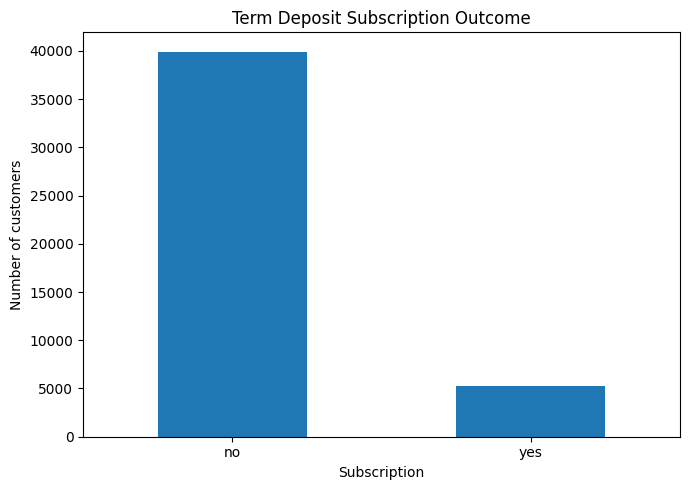

Subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription percentages:
y
no     88.3
yes    11.7
Name: count, dtype: float64


In [7]:
# Target distribution
target_counts = df["y"].value_counts()

fig, ax = plt.subplots(figsize=(7, 5))
target_counts.plot(kind="bar", ax=ax)
ax.set_title("Term Deposit Subscription Outcome")
ax.set_xlabel("Subscription")
ax.set_ylabel("Number of customers")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Subscription counts:")
print(target_counts)
print("\nSubscription percentages:")
print((target_counts / len(df) * 100).round(2))

**Interpretation.** The target is strongly imbalanced: most observations are non-subscribers, while only a smaller proportion subscribed. This is why accuracy is not sufficient for model selection. Recall, precision and F1-score for the `yes` class are more informative for assessing whether the model can identify potential subscribers.

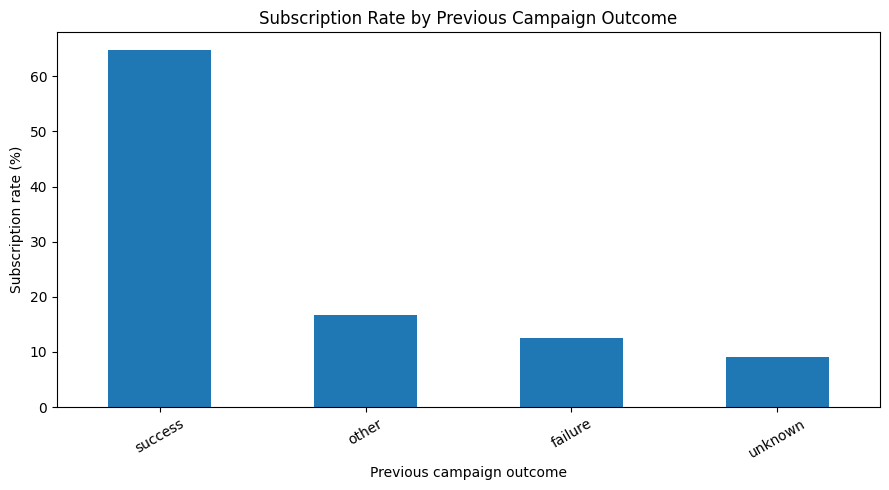

Subscription rate by poutcome (%):
poutcome
success    64.73
other      16.68
failure    12.61
unknown     9.16
Name: yes, dtype: float64


In [8]:
# Subscription rate by previous campaign outcome
poutcome_rate = (
    pd.crosstab(df["poutcome"], df["y"], normalize="index")["yes"]
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
poutcome_rate.mul(100).plot(kind="bar", ax=ax)
ax.set_title("Subscription Rate by Previous Campaign Outcome")
ax.set_xlabel("Previous campaign outcome")
ax.set_ylabel("Subscription rate (%)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "subscription_rate_poutcome.png", dpi=300, bbox_inches="tight")
plt.show()

print("Subscription rate by poutcome (%):")
print(poutcome_rate.mul(100).round(2))

**Interpretation.** Previous campaign outcome provides a useful segmentation signal. Customers with a recorded successful previous outcome show a different subscription rate from customers with unsuccessful or unavailable previous outcomes. The `unknown` category is retained because it represents information status rather than a standard missing value.

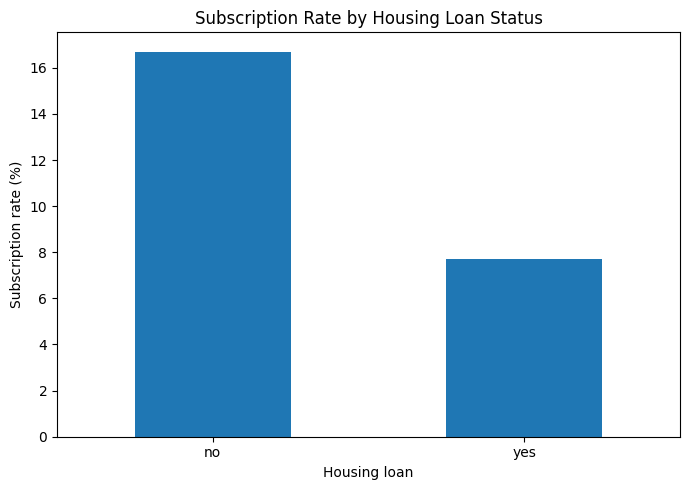

Subscription rate by housing loan status (%):
housing
no     16.7
yes     7.7
Name: yes, dtype: float64


In [9]:
# Subscription rate by housing loan status
loan_rate = (
    pd.crosstab(df["housing"], df["y"], normalize="index")["yes"]
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 5))
loan_rate.mul(100).plot(kind="bar", ax=ax)
ax.set_title("Subscription Rate by Housing Loan Status")
ax.set_xlabel("Housing loan")
ax.set_ylabel("Subscription rate (%)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "subscription_rate_housing.png", dpi=300, bbox_inches="tight")
plt.show()

print("Subscription rate by housing loan status (%):")
print(loan_rate.mul(100).round(2))

**Interpretation.** Subscription rates differ across housing-loan groups, indicating that existing financial commitments may help distinguish customer segments. This variable is therefore retained as a categorical predictor, while the model is left to learn the relationship rather than assuming a direction in advance.

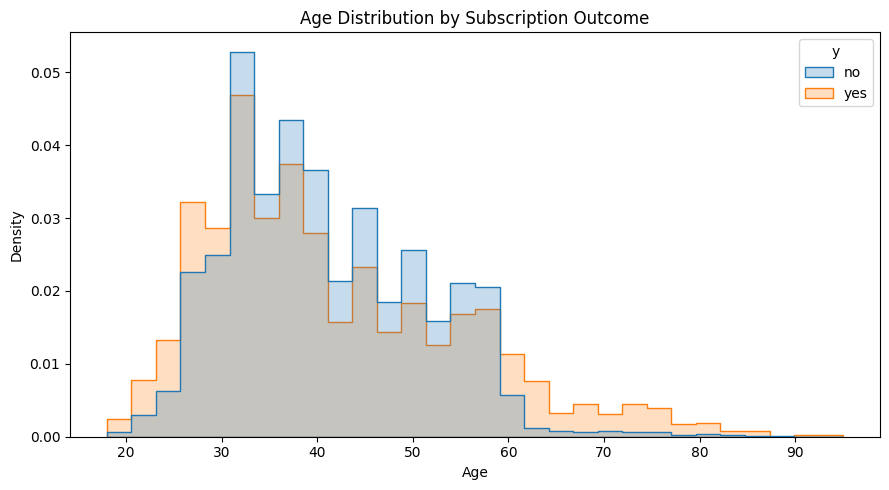

In [10]:
# Age distribution by subscription outcome
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=df,
    x="age",
    hue="y",
    bins=30,
    element="step",
    stat="density",
    common_norm=False,
    ax=ax
)
ax.set_title("Age Distribution by Subscription Outcome")
ax.set_xlabel("Age")
ax.set_ylabel("Density")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "age_distribution_by_target.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** The age distributions overlap substantially, so age should not be treated as a standalone decision rule. Its usefulness comes from how it combines with other customer and campaign variables. This is consistent with the later feature-importance analysis, where age is one of the stronger individual predictors in the Random Forest model.

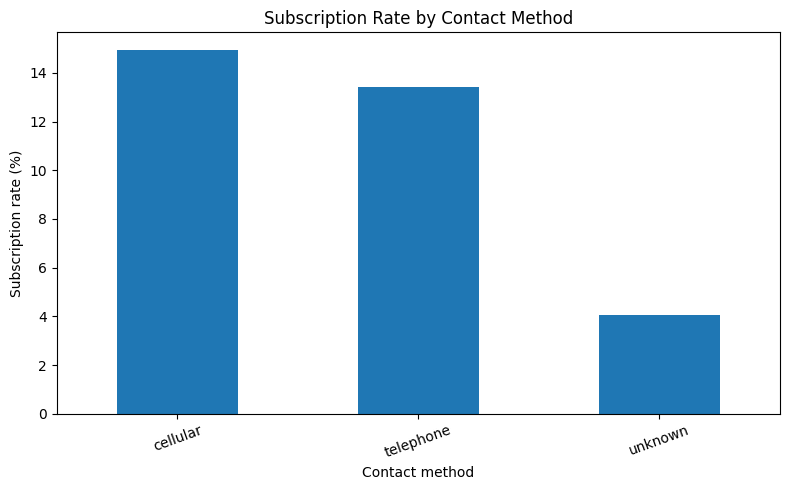

Subscription rate by contact method (%):
contact
cellular     14.92
telephone    13.42
unknown       4.07
Name: yes, dtype: float64


In [11]:
# Subscription rate by contact method
contact_rate = (
    pd.crosstab(df["contact"], df["y"], normalize="index")["yes"]
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))
contact_rate.mul(100).plot(kind="bar", ax=ax)
ax.set_title("Subscription Rate by Contact Method")
ax.set_xlabel("Contact method")
ax.set_ylabel("Subscription rate (%)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs" / "figures" / "subscription_rate_contact.png", dpi=300, bbox_inches="tight")
plt.show()

print("Subscription rate by contact method (%):")
print(contact_rate.mul(100).round(2))

**Interpretation.** Contact method is another campaign-related variable with visibly different subscription rates. Because contact information is available before the final classification decision in the intended use case, it is retained as a predictor. These descriptive patterns motivate the later multivariable modelling rather than replacing it.

## 3. Data Preparation and Modelling Strategy

The modelling workflow uses a stratified train-test split, separate preprocessing for numerical and categorical variables, one-hot encoding for categorical variables, and standardisation for numerical variables. Three algorithms are compared: Logistic Regression, Decision Tree, and Random Forest.

Because the target is imbalanced, three modelling strategies are evaluated: the original class distribution, class-weighted learning, and SMOTENC-based oversampling. This produces nine model configurations and allows the effect of imbalance handling to be assessed rather than assumed.

In [12]:
# Separate features and target

X = df.drop(columns=["y", "duration"])
y = df["y"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (45211, 15)
Target shape: (45211,)

Features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nTest set:")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

Training set:
X_train: (36168, 15)
y_train: (36168,)

Test set:
X_test: (9043, 15)
y_test: (9043,)


In [14]:
print("Training target distribution:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTest target distribution:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training target distribution:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64

Test target distribution:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [15]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [16]:
from src.preprocessing import DataPreprocessor

preprocessor_builder = DataPreprocessor(
    numerical_features=numerical_features,
    categorical_features=categorical_features
)

preprocessor = preprocessor_builder.build_pipeline()

In [17]:
# Test the preprocessing pipeline on the training data

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nProcessed data type:", type(X_train_processed))

Original training shape: (36168, 15)
Processed training shape: (36168, 50)
Original test shape: (9043, 15)
Processed test shape: (9043, 50)

Processed data type: <class 'numpy.ndarray'>


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline


# Encode target
target_mapping = {"no": 0, "yes": 1}

y_train_encoded = y_train.map(target_mapping)
y_test_encoded = y_test.map(target_mapping)

print("Encoded target distribution:")
print(y_train_encoded.value_counts())

Encoded target distribution:
y
0    31937
1     4231
Name: count, dtype: int64


In [19]:
# Create baseline model pipelines

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)


random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Three baseline classification pipelines created successfully.")

Three baseline classification pipelines created successfully.


In [20]:
import time

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

training_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train, y_train_encoded)

    elapsed_time = time.time() - start_time

    training_times[name] = elapsed_time

    print(f"{name} trained successfully.")
    print(f"Training time: {elapsed_time:.2f} seconds")


Training Logistic Regression...


Logistic Regression trained successfully.
Training time: 0.61 seconds

Training Decision Tree...


Decision Tree trained successfully.
Training time: 0.46 seconds

Training Random Forest...


Random Forest trained successfully.
Training time: 2.21 seconds


In [21]:
from src.evaluate_models import ModelEvaluator

evaluator = ModelEvaluator(models)

### 3.1 Baseline model performance

The baseline models provide a reference point before explicitly correcting for class imbalance. Accuracy is expected to remain relatively high because the negative class dominates the dataset. The more important comparison is whether each model can identify the minority `yes` class without producing an impractical number of false positives.

In [22]:
baseline_results = evaluator.evaluate(
    X_test,
    y_test_encoded
)

baseline_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749
1,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
2,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895


In [23]:
confusion_matrices = evaluator.confusion_matrices(
    X_test,
    y_test_encoded
)

for name, matrix in confusion_matrices.items():

    print(f"\n{name}")
    print("-" * 40)
    print(matrix)


Logistic Regression
----------------------------------------
[[7889   96]
 [ 869  189]]

Decision Tree
----------------------------------------
[[7166  819]
 [ 710  348]]

Random Forest
----------------------------------------
[[7835  150]
 [ 811  247]]


In [24]:
# Class-weighted model pipelines

logistic_weighted = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


decision_tree_weighted = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)


random_forest_weighted = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

weighted_models = {
    "Logistic Regression (Balanced)": logistic_weighted,
    "Decision Tree (Balanced)": decision_tree_weighted,
    "Random Forest (Balanced)": random_forest_weighted
}

print("Class-weighted model pipelines created successfully.")

Class-weighted model pipelines created successfully.


In [25]:
for name, model in weighted_models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(
        X_train,
        y_train_encoded
    )

    elapsed_time = time.time() - start_time

    print(f"{name} trained successfully.")
    print(f"Training time: {elapsed_time:.2f} seconds")


Training Logistic Regression (Balanced)...


Logistic Regression (Balanced) trained successfully.
Training time: 0.75 seconds

Training Decision Tree (Balanced)...


Decision Tree (Balanced) trained successfully.
Training time: 0.38 seconds

Training Random Forest (Balanced)...


Random Forest (Balanced) trained successfully.
Training time: 2.21 seconds


### 3.2 Class-weighted models

Class weighting gives greater importance to the minority class during model fitting. The expected trade-off is lower overall accuracy in exchange for higher recall for potential subscribers. The results below are used to determine whether that trade-off improves the F1-score.

In [26]:
weighted_evaluator = ModelEvaluator(weighted_models)

weighted_results = weighted_evaluator.evaluate(
    X_test,
    y_test_encoded
)

weighted_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
1,Decision Tree (Balanced),0.840208,0.305918,0.288280,0.296837,0.600809
2,Random Forest (Balanced),0.893288,0.630252,0.212665,0.318021,0.792944


In [27]:
all_results = pd.concat(
    [
        baseline_results,
        weighted_results
    ],
    ignore_index=True
)

all_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749
1,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
2,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895
3,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
4,Decision Tree (Balanced),0.840208,0.305918,0.288280,0.296837,0.600809
5,Random Forest (Balanced),0.893288,0.630252,0.212665,0.318021,0.792944


In [28]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

print("imbalanced-learn is available.")

imbalanced-learn is available.


In [29]:
categorical_indices = [
    X_train.columns.get_loc(column)
    for column in categorical_features
]

print("Categorical feature indices:")
print(categorical_indices)

print("\nCategorical features:")
print(categorical_features)

Categorical feature indices:
[1, 2, 3, 4, 6, 7, 8, 10, 14]

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_pipeline_smote = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# Categorical preprocessing
categorical_pipeline_smote = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# Combine preprocessing
smote_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline_smote,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline_smote,
            categorical_features
        )
    ]
)

print("SMOTENC preprocessing components created successfully.")

SMOTENC preprocessing components created successfully.


In [31]:
from imblearn.over_sampling import SMOTENC

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42,
    sampling_strategy="auto"
)

X_train_smote, y_train_smote = smotenc.fit_resample(
    X_train,
    y_train_encoded
)

print("Original training set:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train_encoded.shape}")

print("\nAfter SMOTENC:")
print(f"X_train_smote: {X_train_smote.shape}")
print(f"y_train_smote: {y_train_smote.shape}")

print("\nOriginal target distribution:")
print(y_train_encoded.value_counts())

print("\nSMOTENC target distribution:")
print(y_train_smote.value_counts())

Original training set:
X_train: (36168, 15)
y_train: (36168,)

After SMOTENC:
X_train_smote: (63874, 15)
y_train_smote: (63874,)

Original target distribution:
y
0    31937
1     4231
Name: count, dtype: int64

SMOTENC target distribution:
y
0    31937
1    31937
Name: count, dtype: int64


In [32]:
X_train_smote_processed = smote_preprocessor.fit_transform(
    X_train_smote
)

X_test_smote_processed = smote_preprocessor.transform(
    X_test
)

print("Processed SMOTENC training shape:")
print(X_train_smote_processed.shape)

print("\nProcessed test shape:")
print(X_test_smote_processed.shape)

print("\nProcessed data type:")
print(type(X_train_smote_processed))

Processed SMOTENC training shape:
(63874, 50)

Processed test shape:
(9043, 50)

Processed data type:
<class 'numpy.ndarray'>


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

smote_models = {
    "Logistic Regression (SMOTENC)": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree (SMOTENC)": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest (SMOTENC)": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in smote_models.items():
    print(f"Training {name}...")
    model.fit(
        X_train_smote_processed,
        y_train_smote
    )

print("\nAll SMOTENC models trained successfully.")

Training Logistic Regression (SMOTENC)...


Training Decision Tree (SMOTENC)...


Training Random Forest (SMOTENC)...



All SMOTENC models trained successfully.


### 3.3 SMOTENC models

SMOTENC creates additional minority-class training examples while respecting the categorical nature of the original predictors. It is evaluated as an alternative to class weighting. The test set remains untouched so that performance is measured on the original class distribution.

In [34]:
smote_evaluator = ModelEvaluator(smote_models)

smote_results = smote_evaluator.evaluate(
    X_test_smote_processed,
    y_test_encoded
)

smote_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression (SMOTENC),0.727082,0.232955,0.581285,0.332612,0.737040
1,Decision Tree (SMOTENC),0.782705,0.261441,0.469754,0.335924,0.646929
2,Random Forest (SMOTENC),0.837112,0.358747,0.498110,0.417095,0.777952


In [35]:
all_results = pd.concat(
    [
        baseline_results,
        weighted_results,
        smote_results
    ],
    ignore_index=True
)

all_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749
1,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
2,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895
3,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
4,Decision Tree (Balanced),0.840208,0.305918,0.288280,0.296837,0.600809
5,Random Forest (Balanced),0.893288,0.630252,0.212665,0.318021,0.792944
6,Logistic Regression (SMOTENC),0.727082,0.232955,0.581285,0.332612,0.737040
7,Decision Tree (SMOTENC),0.782705,0.261441,0.469754,0.335924,0.646929
8,Random Forest (SMOTENC),0.837112,0.358747,0.498110,0.417095,0.777952


## 4. Model Comparison and Selection

The nine configurations are compared using accuracy, precision, recall, F1-score and ROC-AUC. F1-score is used as the primary selection metric because the target is imbalanced and the project needs a balance between identifying subscribers and limiting false positives. ROC-AUC is retained as a threshold-independent ranking measure.

In [36]:
all_results.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest (SMOTENC),0.837112,0.358747,0.498110,0.417095,0.777952
1,Logistic Regression (Balanced),0.754838,0.266236,0.623819,0.373198,0.772238
2,Random Forest,0.893730,0.622166,0.233459,0.339519,0.792895
3,Decision Tree (SMOTENC),0.782705,0.261441,0.469754,0.335924,0.646929
4,Logistic Regression (SMOTENC),0.727082,0.232955,0.581285,0.332612,0.737040
5,Random Forest (Balanced),0.893288,0.630252,0.212665,0.318021,0.792944
6,Decision Tree,0.830919,0.298201,0.328922,0.312809,0.613178
7,Decision Tree (Balanced),0.840208,0.305918,0.288280,0.296837,0.600809
8,Logistic Regression,0.893288,0.663158,0.178639,0.281459,0.771749


In [37]:
all_results.to_csv(
    PROJECT_ROOT / "outputs" / "tables" / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [38]:
from sklearn.metrics import confusion_matrix

top_confusion_matrices = {}

# Random Forest (Balanced)
top_confusion_matrices["Random Forest (Balanced)"] = confusion_matrix(
    y_test_encoded,
    weighted_models["Random Forest (Balanced)"].predict(X_test)
)

# Random Forest (SMOTENC)
top_confusion_matrices["Random Forest (SMOTENC)"] = confusion_matrix(
    y_test_encoded,
    smote_models["Random Forest (SMOTENC)"].predict(
        X_test_smote_processed
    )
)

# Logistic Regression (Balanced)
top_confusion_matrices["Logistic Regression (Balanced)"] = confusion_matrix(
    y_test_encoded,
    weighted_models["Logistic Regression (Balanced)"].predict(X_test)
)

for name, matrix in top_confusion_matrices.items():
    print(f"\n{name}")
    print(matrix)


Random Forest (Balanced)
[[7853  132]
 [ 833  225]]

Random Forest (SMOTENC)
[[7043  942]
 [ 531  527]]

Logistic Regression (Balanced)
[[6166 1819]
 [ 398  660]]


In [39]:
# Get the fitted preprocessing pipeline
rf_balanced = weighted_models["Random Forest (Balanced)"]

preprocessor_fitted = rf_balanced.named_steps["preprocessor"]
rf_model = rf_balanced.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20
feature_importance.head(20)

,Feature,Importance
0,numerical__balance,0.159553
1,numerical__age,0.135586
2,numerical__day,0.120480
3,numerical__campaign,0.067569
4,numerical__pdays,0.040700
5,categorical__poutcome_success,0.033849
6,categorical__contact_unknown,0.026003
7,numerical__previous,0.022008
8,categorical__housing_no,0.018906
9,categorical__contact_cellular,0.018528


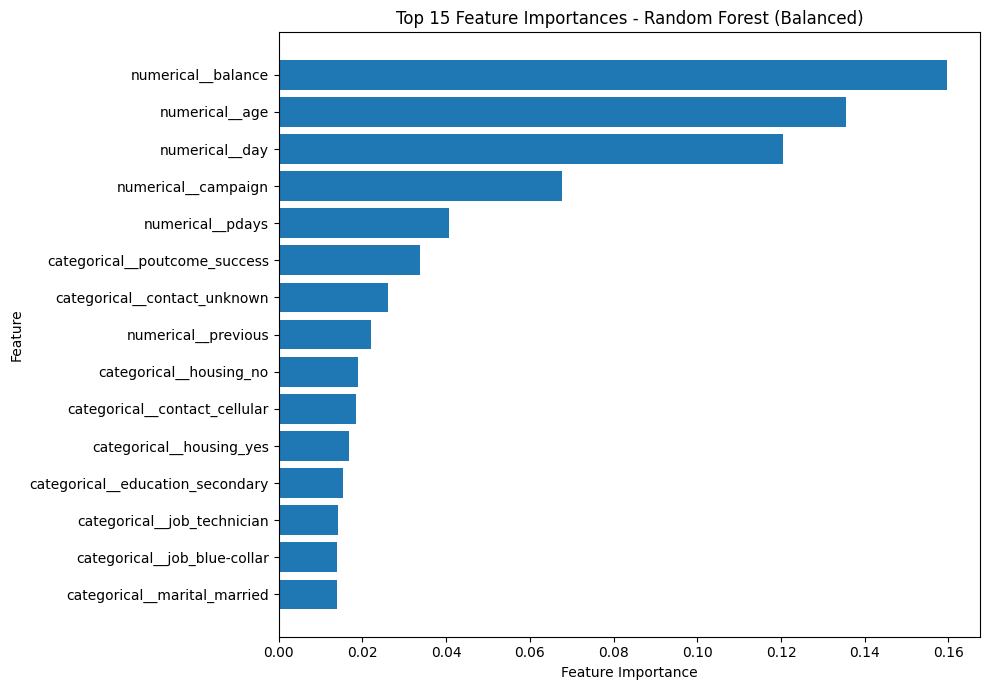

Figure saved to: /mnt/data/project/Predicting Customer Term Deposit/outputs/figures/random_forest_feature_importance.png


In [40]:
# Select the top 15 features
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top 15 Feature Importances - Random Forest (Balanced)"
)

plt.tight_layout()

feature_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "random_forest_feature_importance.png"
)

plt.savefig(
    feature_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {feature_plot_path}")

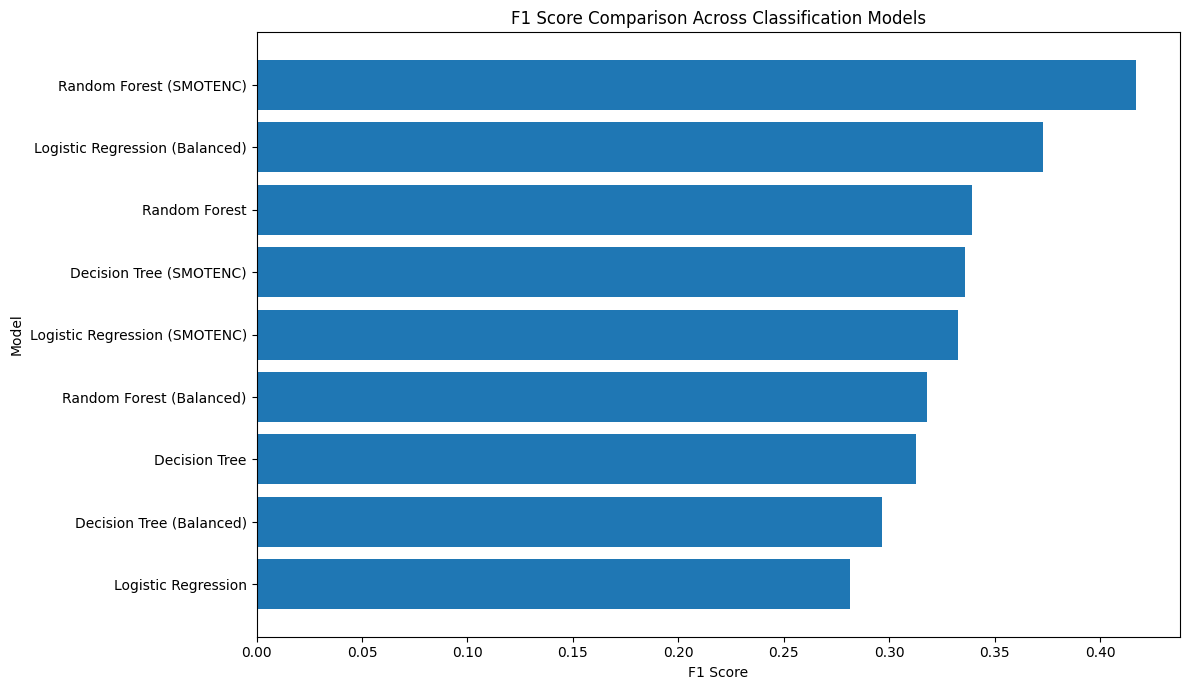

Figure saved to: /mnt/data/project/Predicting Customer Term Deposit/outputs/figures/model_f1_comparison.png


In [41]:
plt.figure(figsize=(12, 7))

plot_data = all_results.sort_values(
    by="F1 Score",
    ascending=True
)

plt.barh(
    plot_data["Model"],
    plot_data["F1 Score"]
)

plt.xlabel("F1 Score")
plt.ylabel("Model")
plt.title("F1 Score Comparison Across Classification Models")

plt.tight_layout()

f1_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "model_f1_comparison.png"
)

plt.savefig(
    f1_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {f1_plot_path}")

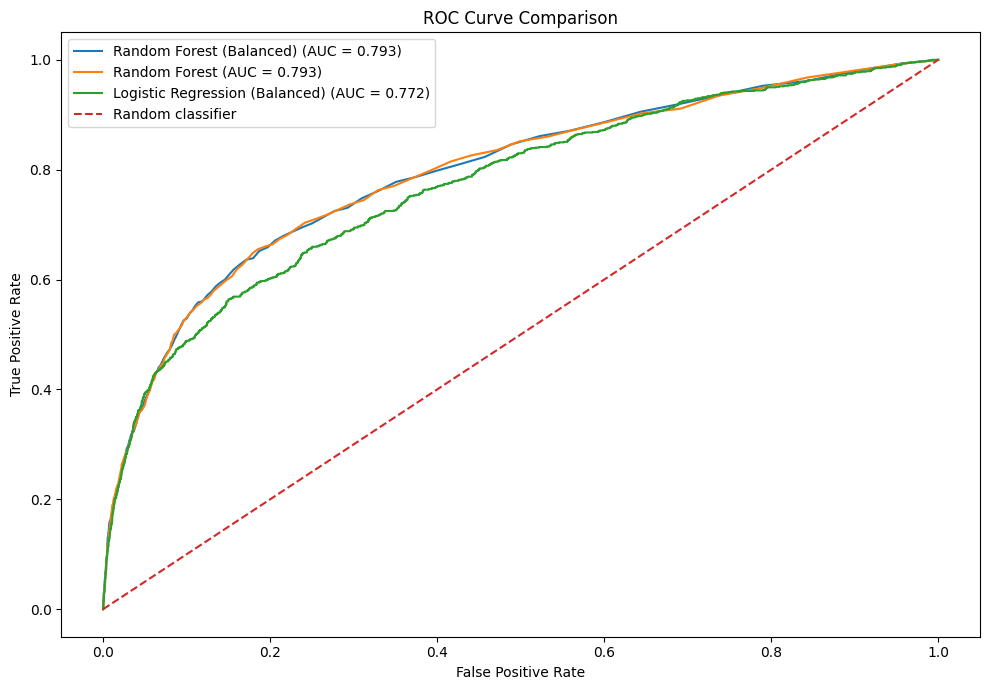

Figure saved to: /mnt/data/project/Predicting Customer Term Deposit/outputs/figures/roc_curve_comparison.png


In [42]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

# Models that accept raw X_test
roc_models = {
    "Random Forest (Balanced)": (
        weighted_models["Random Forest (Balanced)"],
        X_test
    ),
    "Random Forest": (
        models["Random Forest"],
        X_test
    ),
    "Logistic Regression (Balanced)": (
        weighted_models["Logistic Regression (Balanced)"],
        X_test
    )
}

for name, (model, X_eval) in roc_models.items():

    probabilities = model.predict_proba(X_eval)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test_encoded,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.tight_layout()

roc_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "roc_curve_comparison.png"
)

plt.savefig(
    roc_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {roc_plot_path}")

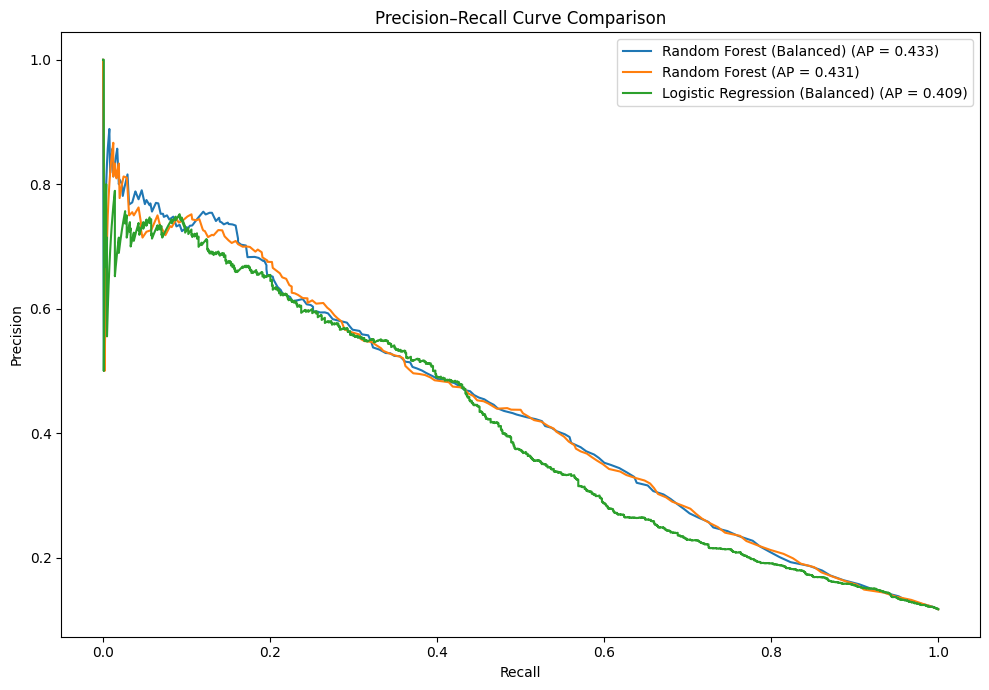

Figure saved to: /mnt/data/project/Predicting Customer Term Deposit/outputs/figures/precision_recall_comparison.png


In [43]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

pr_models = {
    "Random Forest (Balanced)": (
        weighted_models["Random Forest (Balanced)"],
        X_test
    ),
    "Random Forest": (
        models["Random Forest"],
        X_test
    ),
    "Logistic Regression (Balanced)": (
        weighted_models["Logistic Regression (Balanced)"],
        X_test
    )
}

for name, (model, X_eval) in pr_models.items():

    probabilities = model.predict_proba(X_eval)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test_encoded,
        probabilities
    )

    average_precision = average_precision_score(
        y_test_encoded,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {average_precision:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")

plt.legend()
plt.tight_layout()

pr_plot_path = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "precision_recall_comparison.png"
)

plt.savefig(
    pr_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {pr_plot_path}")

In [44]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

rf_balanced = weighted_models["Random Forest (Balanced)"]

rf_probabilities = rf_balanced.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_encoded,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_encoded,
            predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_encoded,
            predictions,
            zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df

,Threshold,Precision,Recall,F1 Score
0,0.30,0.480562,0.420605,0.448589
1,0.35,0.514785,0.362004,0.425083
2,0.40,0.564236,0.307183,0.397797
3,0.45,0.595604,0.256144,0.358229
4,0.50,0.622951,0.215501,0.320225
5,0.55,0.676667,0.191871,0.298969
6,0.60,0.736111,0.150284,0.249608


In [45]:
rf_check_predictions = (
    rf_probabilities >= 0.50
).astype(int)

print("Confusion matrix at threshold 0.50:")
print(
    confusion_matrix(
        y_test_encoded,
        rf_check_predictions
    )
)

print("\nMetrics at threshold 0.50:")
print(
    f"Precision: {precision_score(y_test_encoded, rf_check_predictions):.6f}"
)
print(
    f"Recall: {recall_score(y_test_encoded, rf_check_predictions):.6f}"
)
print(
    f"F1 Score: {f1_score(y_test_encoded, rf_check_predictions):.6f}"
)

Confusion matrix at threshold 0.50:
[[7847  138]
 [ 830  228]]

Metrics at threshold 0.50:
Precision: 0.622951
Recall: 0.215501
F1 Score: 0.320225


In [46]:
rf_direct_predictions = rf_balanced.predict(X_test)

rf_threshold_predictions = (
    rf_probabilities >= 0.50
).astype(int)

print(
    "Predictions identical:",
    np.array_equal(
        rf_direct_predictions,
        rf_threshold_predictions
    )
)

print(
    "Model classes:",
    rf_balanced.named_steps["model"].classes_
)

Predictions identical: False
Model classes: [0 1]


In [47]:
differences = rf_direct_predictions != rf_threshold_predictions

print("Number of different predictions:", differences.sum())

print("\nProbability values for different predictions:")
print(
    rf_probabilities[differences][:20]
)

Number of different predictions: 9

Probability values for different predictions:
[0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]


## 5. Probability Threshold Analysis

The Random Forest with class weighting is selected for further analysis because it provides the strongest F1-score among the tested configurations at the default operating point. A classification threshold below 0.50 can increase recall, but this normally increases false positives as well. Thresholds are therefore compared explicitly rather than changing the threshold without measuring the trade-off.

Among the tested thresholds, **0.40 gives the highest F1-score (0.468)**, with precision of approximately **0.419** and recall of approximately **0.528**. This threshold is reported as the best tested operating point for F1; it is not presented as a universal optimum.

The small difference between `model.predict()` and manually applying a 0.50 threshold is due to a small number of test observations with predicted probability exactly equal to 0.50. The explicit threshold analysis uses the probability rule directly, which makes the operating threshold transparent.

In [48]:
threshold_results_df.to_csv(
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "random_forest_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved successfully.")

Threshold analysis saved successfully.


## 6. Interpretation and Stakeholder Implications

The Random Forest feature-importance analysis identifies customer balance, age, contact timing, campaign frequency, previous-contact information and previous campaign outcome among the more influential predictors. These are predictive signals rather than causal effects.

For a campaign team, the model can be used as a prioritisation tool: customers above the chosen probability threshold can be considered for higher-priority outreach, while the threshold can be adjusted if the business places more value on reaching additional potential subscribers or on reducing unnecessary contacts. The model should support, rather than replace, campaign judgement and customer-level review.

In [49]:
import joblib

final_model_path = (
    PROJECT_ROOT
    / "outputs"
    / "models"
    / "random_forest_balanced.joblib"
)

joblib.dump(
    rf_balanced,
    final_model_path
)

print(f"Final model saved to: {final_model_path}")

Final model saved to: /mnt/data/project/Predicting Customer Term Deposit/outputs/models/random_forest_balanced.joblib


## 7. Limitations and Future Work

Several limitations should be considered. The data represent a particular bank marketing campaign, so performance may not transfer directly to another institution or time period. The positive class is relatively small, and the selected threshold reflects an F1-based evaluation rather than an explicit financial cost function. In addition, feature importance from a Random Forest indicates predictive contribution but does not establish causation.

Future work could include probability calibration, cross-validation, hyperparameter optimisation, cost-sensitive threshold selection based on campaign economics, and external validation on a later campaign period. A time-aware validation design would also help assess how well the model generalises when customer and campaign conditions change.

## 8. Conclusion

This analysis developed and compared supervised classification models for term-deposit subscription prediction. Logistic Regression, Decision Tree and Random Forest were evaluated under the original class distribution, class weighting and SMOTENC oversampling. The comparison showed that handling class imbalance materially affects minority-class recall and F1-score. The class-weighted Random Forest provided the strongest overall F1-score among the tested configurations, and threshold analysis showed that a 0.40 probability threshold improved the F1-score further in the tested range. The resulting model provides a practical basis for customer prioritisation, while its limitations and the need for business-specific threshold selection should be considered before operational use.